# 6주차 추가 실습 · PyTorch로 신경망 학습하기

**이번 실습:** 3주차와 같은 공정 표에서 막 두께를 예측하며 신경망 학습의 내부 순서를 직접 봅니다. 기존 `06주차_신경망_검증하기.ipynb`는 분류·검증 실습이고, 이 파일은 `class`, 자동 미분, 학습 반복문의 역할을 배우는 별도 실습입니다.

기본 구역 1~9를 위에서부터 실행합니다. CNN·RNN은 맨 아래 선택 구역입니다. GPU는 필요하지 않습니다. 오른쪽 위 커널은 **Python (semi-ai)**를 선택합니다. 저장된 출력은 제공 자료로 실제 실행한 예시이며 소수점 값은 설치 버전에 따라 조금 달라질 수 있습니다.

PyTorch도 `environment.yml`에 포함되어 있습니다. 새 환경은 터미널에서 `conda env create -f environment.yml`로 만들고, 기존 환경은 `conda env update -n semi-ai -f environment.yml`로 업데이트합니다. 그 뒤 Python (semi-ai) 커널을 다시 시작합니다. 기존 Python 3.10·NumPy 1.24 수업 환경에 맞춘 torch 2.0.1을 함께 설치합니다. 자세한 순서는 README의 **PyTorch 설치도 environment.yml에 포함**을 보세요.

## 0. 실습 폴더 준비

VS Code와 Colab 어디서 열어도 `data` 폴더를 찾도록 실습 폴더 위치를 정합니다. Colab에서는 처음 한 번 실습 자료를 내려받습니다.

In [ ]:
import sys, subprocess  # 실행 환경 확인과 명령 실행 도구입니다.
from pathlib import Path  # 파일 위치 도구입니다.
if "google.colab" in sys.modules:  # Colab에서 실행 중이라면
    folder = Path("/content/semiconductor_ai_beginner")  # 실습 자료를 둘 위치입니다.
    if not folder.exists():  # 아직 내려받지 않았다면
        subprocess.run(["git", "clone", "-q", "https://github.com/SeokJH-TAs/semiconductor_ai_beginner.git", str(folder)], check=True)  # 실습 자료 전체를 내려받습니다.
else:  # VS Code 등 내 컴퓨터에서 실행 중이라면
    folder = Path.cwd()  # 현재 폴더입니다.
    if folder.name == "notebooks":  # 노트북 폴더 안이라면
        folder = folder.parent  # 실습 전체 폴더로 올라갑니다.
print(folder)  # 실습 폴더 위치를 확인합니다.

## 1. 도구와 표 불러오기

`torch.Tensor`는 PyTorch가 계산하는 숫자 묶음입니다. `nn`은 신경망 층과 손실 함수를 모아 둔 도구입니다. 이번 데이터는 240개의 **독립 공정 기록**이며 영상이나 시계열 자료가 아닙니다.

In [1]:
from pathlib import Path  # 파일 위치 도구입니다.
import pandas as pd  # 표를 읽는 도구입니다.
import numpy as np  # 배열 계산 도구입니다.
import matplotlib.pyplot as plt  # 그림 도구입니다.
plt.rcParams["font.size"] = 14  # 발표 화면에서도 축 글자를 읽기 쉽게 키웁니다.
import torch  # 텐서와 자동 미분 도구입니다.
from torch import nn  # 신경망 도구를 꺼냅니다.
from torch.utils.data import TensorDataset, DataLoader  # 짝 묶기와 배달 도구입니다.
from sklearn.model_selection import train_test_split  # 학습·시험 분리 도구입니다.
from sklearn.preprocessing import StandardScaler  # 입력 크기를 맞추는 도구입니다.
data = pd.read_csv(folder / "data" / "process.csv")  # 기존 공정 표입니다.
print("PyTorch:", torch.__version__)  # 실제 실행 버전을 봅니다.
print(data.head(3))  # 처음 세 행을 봅니다.

PyTorch: 2.0.1
  sample_id  temperature_c  pressure_torr  gas_flow_sccm  rf_power_w  \
0      W001        413.698          1.664        110.439     221.019   
1      W002        396.944          1.637        100.881     214.638   
2      W003        417.930          1.186        119.415     182.867   

   thickness_nm  defect  
0       104.018       1  
1        97.325       0  
2       107.485       1  


## 2. 표를 텐서로 바꾸기

3주차처럼 온도·유량·전력으로 두께를 예상합니다. 표준화는 학습 입력으로만 배웁니다. 두께는 `(두께-100)/10`으로 작게 바꾸고 마지막에 다시 nm로 되돌립니다. 100과 10은 이 실습에서 미리 정한 단위 변환 상수입니다.

`float32`는 소수 계산 자료형입니다. `reshape(-1, 1)`의 -1은 행 개수를 자동으로 맞추고, 1은 정답을 한 열로 만든다는 뜻입니다. 예측과 정답을 모두 `(행 수, 1)`로 맞춥니다.

In [2]:
X = data[["temperature_c", "gas_flow_sccm", "rf_power_w"]]  # 입력 세 열입니다.
y = data["thickness_nm"]  # 정답 두께입니다.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)  # 3주차와 같은 분할입니다.
scaler = StandardScaler()  # 입력 표준화 도구입니다.
train_x = torch.tensor(scaler.fit_transform(X_train), dtype=torch.float32)  # 학습 입력입니다.
test_x = torch.tensor(scaler.transform(X_test), dtype=torch.float32)  # 같은 기준의 시험 입력입니다.
train_y = torch.tensor((y_train.to_numpy() - 100) / 10, dtype=torch.float32).reshape(-1, 1)  # 정답 한 열입니다.
print("입력:", train_x.shape, "정답:", train_y.shape)  # (180, 3), (180, 1)입니다.
print(train_x[:2])  # 앞 두 행의 입력입니다.
print(train_y[:2])  # 짝이 맞는 앞 두 정답입니다.

입력: torch.Size([180, 3]) 정답: torch.Size([180, 1])
tensor([[ 0.4734, -0.0508,  1.4578],
        [-0.5430,  1.2322, -0.2065]])
tensor([[0.1203],
        [0.2919]])


## 3. Dataset과 DataLoader

`TensorDataset`은 같은 행의 입력과 정답을 짝지어 보관합니다. `DataLoader`는 그 짝을 작은 묶음 **배치**로 꺼내 줍니다. `batch_size=16`은 한 번에 최대 16행, `shuffle=True`는 학습 순서를 섞는다는 뜻입니다. 180행이므로 한 바퀴에 12배치이며 마지막은 4행입니다.

`next(iter(loader))`는 배달을 시작해서 첫 묶음만 꺼내는 표현입니다. 반복 학습에서는 `for batch_x, batch_y in loader`를 사용합니다. `num_workers=0`으로 별도 작업 프로세스를 만들지 않아 노트북에서도 단순하게 실행합니다.

In [3]:
torch.manual_seed(42)  # 순서와 시작값을 재현하기 위한 씨앗입니다.
dataset = TensorDataset(train_x, train_y)  # 입력·정답 짝 180개입니다.
loader = DataLoader(dataset, batch_size=16, shuffle=True, num_workers=0)  # 작은 묶음을 꺼냅니다.
batch_x, batch_y = next(iter(loader))  # 첫 배치 하나를 꺼냅니다.
print("기록 수:", len(dataset), "배치 수:", len(loader))  # 180과 12입니다.
print("배치 모양:", batch_x.shape, batch_y.shape)  # (16, 3), (16, 1)입니다.
print("첫 입력:", batch_x[0])  # 이 배치의 첫 공정 조건입니다.
print("첫 정답:", batch_y[0])  # 같은 기록의 변환한 두께입니다.

기록 수: 180 배치 수: 12
배치 모양: torch.Size([16, 3]) torch.Size([16, 1])
첫 입력: tensor([-1.1371, -0.0886,  1.0711])
첫 정답: tensor([-0.4474])


## 4. class와 nn.Module

`class`는 같은 구조의 모델을 만드는 설계도입니다. `SmallNetwork()`를 실행하면 실제 모델 하나가 생깁니다. 괄호 안의 `nn.Module`을 물려받아 층·가중치를 등록하고 `parameters()`, `train()`, `eval()` 기능을 사용합니다.

`self`는 지금 만든 모델 자신입니다. `__init__`은 모델을 처음 만들 때 층을 준비하고, `super().__init__()`은 부모인 nn.Module을 준비합니다. `forward`에는 입력에서 예측까지의 계산만 적습니다. `network(batch_x)`가 이 계산을 호출합니다. 역전파는 forward 안에 쓰지 않습니다.

입력 `(배치, 3)`을 Linear로 `(배치, 8)`, Tanh로 -1~1 사이 값, 마지막 Linear로 `(배치, 1)`로 바꿉니다. 회귀 출력층에는 sigmoid를 붙이지 않습니다.

In [4]:
class SmallNetwork(nn.Module):  # nn.Module 기능을 가진 새 모델 설계도입니다.
    def __init__(self):  # 모델을 만들 때 한 번 실행합니다.
        super().__init__()  # nn.Module의 기본 준비를 합니다.
        self.hidden = nn.Linear(3, 8)  # 입력 3개를 은닉 숫자 8개로 바꿉니다.
        self.activation = nn.Tanh()  # 중간 숫자에 비선형 변환을 합니다.
        self.output = nn.Linear(8, 1)  # 은닉 숫자 8개로 두께 하나를 만듭니다.

    def forward(self, x):  # 모델에 입력을 넣으면 실행할 계산입니다.
        hidden = self.hidden(x)  # 첫 층 계산입니다.
        activated = self.activation(hidden)  # 중간 변환입니다.
        prediction = self.output(activated)  # 마지막 층 계산입니다.
        return prediction  # 예측을 호출한 곳으로 돌려줍니다.

In [5]:
torch.manual_seed(42)  # 모델 시작값을 고정합니다.
demo = SmallNetwork()  # 설계도로 실제 모델 하나를 만듭니다.
hidden = demo.hidden(batch_x)  # 중간층 출력을 꺼냅니다.
activated = demo.activation(hidden)  # 활성화 뒤 숫자입니다.
demo_prediction = demo(batch_x)  # forward를 포함한 전체 계산입니다.
print(demo)  # 등록된 층을 봅니다.
print("모양:", batch_x.shape, hidden.shape, demo_prediction.shape)  # 3, 8, 1열입니다.
print("첫 예측:", demo_prediction[:3].detach())  # 미분 연결을 떼고 숫자만 읽습니다.
for name, parameter in demo.named_parameters():  # 등록된 가중치·편향을 하나씩 꺼냅니다.
    print(name, parameter.shape)  # optimizer가 바꿀 숫자들의 이름과 모양입니다.

SmallNetwork(
  (hidden): Linear(in_features=3, out_features=8, bias=True)
  (activation): Tanh()
  (output): Linear(in_features=8, out_features=1, bias=True)
)
모양: torch.Size([16, 3]) torch.Size([16, 8]) torch.Size([16, 1])
첫 예측: tensor([[-0.2930],
        [-0.2871],
        [ 0.2782]])
hidden.weight torch.Size([8, 3])
hidden.bias torch.Size([8])
output.weight torch.Size([1, 8])
output.bias torch.Size([1])


## 5. 한 배치에서 backward와 optimizer 보기

5주차에서는 `dw`를 직접 구했습니다. PyTorch에서는 `loss.backward()`가 연결된 계산을 따라가 가중치의 `.grad`에 기울기를 채웁니다. 이 줄만으로 가중치를 바꾸지는 않습니다.

`optimizer`는 등록된 파라미터를 어떤 규칙으로 얼마나 움직일지 정합니다. 여기서는 5주차와 연결되는 SGD를 사용합니다. `step()`이 실제 값을 갱신합니다. `zero_grad(set_to_none=True)`는 이전 기울기 기록을 비웁니다. 생략하면 기울기가 누적됩니다. 초기화 뒤 `.grad`가 `None`인 것은 정상입니다.

아래 `demo`는 한 번만 갱신해 보는 관찰용 모델입니다. 6번에서는 새 모델로 전체 학습을 시작합니다.

In [6]:
loss_function = nn.MSELoss()  # 예측과 정답의 제곱 차이 평균입니다.
optimizer = torch.optim.SGD(demo.parameters(), lr=0.05)  # demo의 숫자를 보폭 0.05로 바꿀 도구입니다.
optimizer.zero_grad(set_to_none=True)  # 지난 기울기를 비웁니다.
print("비운 기울기:", demo.hidden.weight.grad)  # 아직 기울기가 없어 None입니다.
prediction = demo(batch_x)  # 현재 가중치로 예측합니다.
loss = loss_function(prediction, batch_y)  # 정답과 비교한 손실입니다.
print("배치 손실:", loss.item())  # 텐서 속 숫자 하나를 꺼냅니다.
print("갱신 전:", demo.hidden.weight[0].detach().clone())  # 첫 뉴런의 가중치 사본입니다.
loss.backward()  # 각 파라미터의 기울기를 계산합니다.
print("계산한 기울기:", demo.hidden.weight.grad[0])  # 첫 뉴런의 기울기입니다.
optimizer.step()  # 기울기를 사용해 가중치·편향을 바꿉니다.
print("갱신 후:", demo.hidden.weight[0].detach())  # 바뀐 가중치를 봅니다.

비운 기울기: None
배치 손실: 0.17745853960514069
갱신 전: tensor([ 0.4414,  0.4792, -0.1353])
계산한 기울기: tensor([-0.1459,  0.1010,  0.0966])
갱신 후: tensor([ 0.4487,  0.4742, -0.1401])


## 6. main 함수에서 전체 학습하기

`def main():`은 실행 순서를 묶은 함수입니다. 이름 자체에 특별한 학습 기능은 없습니다. 아래에서 `main()`을 호출해야 실행됩니다. 노트북에서는 셀을 순서대로 실행하므로 별도 실행 보호문 없이 호출합니다.

**epoch**는 학습 표를 한 바퀴 도는 횟수입니다. 바깥 반복은 120바퀴, 안쪽 반복은 배치를 하나씩 꺼냅니다. 배치마다 기울기 비우기, 예측, 손실, 역전파, 갱신을 수행합니다. 여기서는 SGD를 여러 번 반복합니다.

기록 손실은 각 배치의 갱신 직전 손실에 행 수를 곱해 합친 뒤 180으로 나눈 값입니다. 마지막 배치가 작아도 행마다 같은 비중으로 셉니다. 시험 자료는 학습에 사용하지 않습니다. 아래 함수가 앞 구역의 `train_x`, `loader` 등을 사용하므로 1~5번을 먼저 실행해야 합니다.

In [7]:
def main():  # 학습 전체의 실행 순서를 묶습니다.
    torch.manual_seed(42)  # 같은 시작 가중치에서 출발합니다.
    network = SmallNetwork()  # 관찰용 demo와 별개인 새 모델입니다.
    loss_function = nn.MSELoss()  # 제곱 오차를 사용합니다.
    optimizer = torch.optim.SGD(network.parameters(), lr=0.05)  # 바꿀 숫자와 보폭을 정합니다.
    history = []  # 한 바퀴마다 손실을 저장합니다.
    with torch.no_grad():  # 관찰용 예측에는 미분 기록이 필요 없습니다.
        before_prediction = network(test_x).numpy() * 10 + 100  # 학습 전 두께를 nm로 되돌립니다.
    network.train()  # 학습 모드입니다. 이것만으로 학습하지는 않습니다.
    for epoch in range(120):  # 전체 학습 표를 120바퀴 봅니다.
        total_loss = 0.0  # 이번 바퀴의 손실 합을 0에서 시작합니다.
        for batch_x, batch_y in loader:  # 입력·정답 배치를 하나씩 받습니다.
            optimizer.zero_grad(set_to_none=True)  # 이전 배치의 기울기를 비웁니다.
            prediction = network(batch_x)  # 순전파로 예측합니다.
            loss = loss_function(prediction, batch_y)  # 정답과 비교합니다.
            loss.backward()  # 기울기를 자동으로 계산합니다.
            optimizer.step()  # 가중치와 편향을 갱신합니다.
            total_loss = total_loss + loss.item() * len(batch_x)  # 행 수를 고려해 더합니다.
        epoch_loss = total_loss / len(dataset)  # 한 행당 평균 손실입니다.
        history.append(epoch_loss)  # 그래프로 볼 기록을 남깁니다.
        if epoch == 0 or (epoch + 1) % 40 == 0:  # 첫 바퀴와 40바퀴마다만
            print("epoch:", epoch + 1, "loss:", round(epoch_loss, 5))  # 진행 상황을 봅니다.
    return network, history, before_prediction  # 결과를 함수 밖으로 꺼냅니다.

In [8]:
network, history, before_prediction = main()  # 위에서 정의한 학습 함수를 실제로 실행합니다.
print("저장한 손실 수:", len(history))  # 120개인지 확인합니다.

epoch: 1 loss: 0.09681


epoch: 40 loss: 0.01521


epoch: 80 loss: 0.01456


epoch: 120 loss: 0.01425
저장한 손실 수: 120


## 7. 손실 곡선

손실이 줄어드는지 봅니다. 세로축은 변환한 두께의 MSE입니다. nm 단위의 RMSE와 같은 숫자가 아닙니다. 학습 손실이 작다는 사실만으로 새로운 자료에도 잘 맞는다고 결론내리지 않습니다.

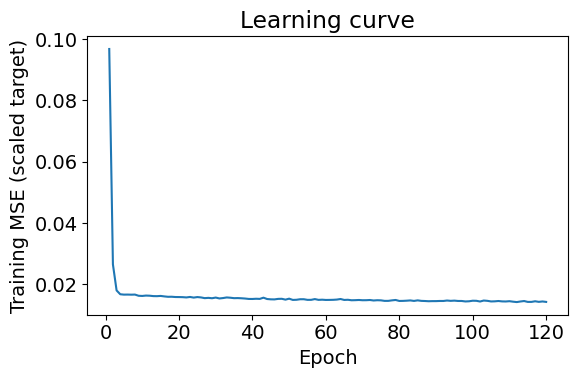

In [9]:
plt.figure(figsize=(6, 4))  # 손실 그림입니다.
plt.plot(range(1, len(history) + 1), history)  # epoch별 손실 기록입니다.
plt.xlabel("Epoch")  # 전체 표를 본 횟수입니다.
plt.ylabel("Training MSE (scaled target)")  # 변환한 정답의 제곱 오차입니다.
plt.title("Learning curve")  # 학습 과정입니다.
plt.tight_layout()  # 여백을 맞춥니다.
plt.show()  # 그림을 보여 줍니다.

## 8. 학습 전·후 시험 예측

`eval()`은 평가 모드로 바꾸고, `no_grad()`는 자동 미분 기록을 끕니다. 둘의 역할은 다릅니다. 이 모델의 Linear·Tanh는 모드 전환에 따라 계산이 달라지지 않지만, Dropout 등을 추가할 때도 같은 습관을 사용합니다.

시험 정답은 학습이 끝난 뒤 결과를 한 번 확인하는 데 사용합니다. 이 점수로 보폭·epoch를 계속 고르려면 기존 6주차처럼 별도의 검증 자료를 만들어야 합니다. 대각선은 실제값과 예측값이 같은 위치입니다.

In [10]:
network.eval()  # 평가 모드로 바꿉니다.
with torch.no_grad():  # 평가에는 기울기를 기록하지 않습니다.
    after_prediction = network(test_x).numpy() * 10 + 100  # nm 단위로 되돌립니다.
actual = y_test.to_numpy().reshape(-1, 1)  # 실제값도 한 열로 맞춥니다.
before_rmse = np.sqrt(np.mean((before_prediction - actual) ** 2))  # 학습 전 시험 오차입니다.
after_rmse = np.sqrt(np.mean((after_prediction - actual) ** 2))  # 학습 후 시험 오차입니다.
print("학습 전 RMSE (nm):", round(before_rmse, 3))  # 학습 전입니다.
print("학습 후 RMSE (nm):", round(after_rmse, 3))  # 학습 후입니다.
print(pd.DataFrame({"actual_nm": actual[:, 0], "predicted_nm": after_prediction[:, 0]}).head())  # 앞 다섯 예측입니다.

학습 전 RMSE (nm): 4.053
학습 후 RMSE (nm): 1.228
   actual_nm  predicted_nm
0    104.813    104.771606
1    106.551    104.915222
2     99.964     99.208824
3    105.160    104.335487
4    105.853    105.493851


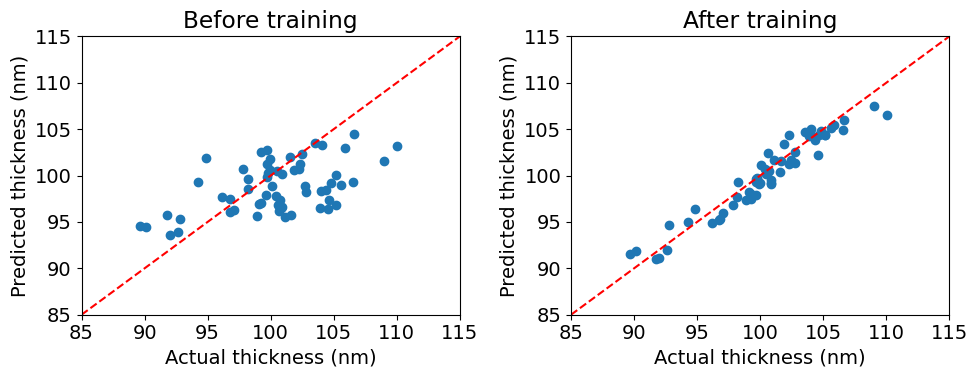

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))  # 나란히 비교할 두 그림입니다.
axes[0].scatter(actual, before_prediction)  # 학습 전 예측입니다.
axes[0].set_title("Before training")  # 왼쪽 제목입니다.
axes[1].scatter(actual, after_prediction)  # 학습 후 예측입니다.
axes[1].set_title("After training")  # 오른쪽 제목입니다.
for axis in axes:  # 두 그림에 같은 기준을 씁니다.
    axis.plot([85, 115], [85, 115], "r--")  # 정확히 맞은 위치입니다.
    axis.set_xlim(85, 115)  # 같은 가로축 범위입니다.
    axis.set_ylim(85, 115)  # 같은 세로축 범위입니다.
    axis.set_xlabel("Actual thickness (nm)")  # 실제 두께입니다.
    axis.set_ylabel("Predicted thickness (nm)")  # 예측 두께입니다.
plt.tight_layout()  # 두 그림 사이 여백을 맞춥니다.
plt.show()  # 전후를 함께 보여 줍니다.

## 9. 역할을 말로 정리하기

| 코드 | 맡은 일 |
|---|---|
| TensorDataset / DataLoader | 입력·정답 짝을 보관 / 배치로 꺼내기 |
| class SmallNetwork(nn.Module) | 모델 설계도와 파라미터 등록 |
| forward / network(x) | 현재 파라미터로 예측 계산 |
| MSELoss | 예측과 정답의 차이를 숫자로 표현 |
| zero_grad | 이전 기울기 기록 비우기 |
| backward | 현재 손실의 기울기 계산 |
| optimizer.step | 기울기를 이용해 파라미터 갱신 |
| main | 이 작업들의 실행 순서 묶기 |

**직접 바꾸기:** `batch_size=16`을 32로 바꾸고 3번부터 실행하세요. 한 바퀴의 배치 수와 첫 배치 모양이 어떻게 바뀌나요? 정답: 6배치, 입력 `(32, 3)`, 정답 `(32, 1)`이고 마지막은 20행입니다. 시험 점수로 여러 설정을 고르는 과제는 아닙니다.

## 선택 A. CNN 문서에서 입력 모양 읽기

**이하 구역은 선택입니다. 학습된 CNN·RNN 성능을 비교하는 과제가 아닙니다.** 공식 문서의 Shape와 Examples를 읽고 한 번 통과하는 모양을 확인합니다.

[Conv2d 공식 문서](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html): 배치 입력은 `(N, C, H, W)`입니다. N은 영상 수, C는 채널 수, H·W는 공간 크기입니다. 아래는 외부 파일 없이 만든 8×8 가상 검사 영상 두 장입니다. 실제 공정 데이터가 아닙니다. 밝은 위치가 다른 단순 숫자 그림입니다.

기존 표의 온도·유량·전력은 단위와 뜻이 다르며 이웃 픽셀 관계가 없습니다. 표를 임의로 네모로 접는 것만으로 의미 있는 CNN 입력이 되지는 않습니다. 영상의 공간 관계가 있는지 먼저 판단합니다.

In [12]:
images = torch.zeros(2, 8, 8)  # 영상 두 장, 높이 8, 너비 8입니다.
images[0, 2:5, 2:5] = 1.0  # 첫 영상의 작은 영역을 밝게 만듭니다.
images[1, 4:7, 4:7] = 1.0  # 둘째 영상은 밝은 위치가 다릅니다.
cnn_input = images.unsqueeze(1)  # 채널 축을 넣어 (2, 1, 8, 8)로 만듭니다.
conv = nn.Conv2d(in_channels=1, out_channels=2, kernel_size=3, padding=1)  # 공간 특징 두 채널입니다.
feature_maps = conv(cnn_input)  # (2, 2, 8, 8) 특징 지도입니다.
pooled = feature_maps.mean(dim=(2, 3))  # 공간 평균으로 영상마다 숫자 두 개를 남깁니다.
cnn_head = nn.Linear(2, 1)  # 특징 두 개로 출력 하나를 만드는 끝 층입니다.
cnn_output = cnn_head(pooled)  # 아직 학습하지 않은 출력입니다.
print("입력:", cnn_input.shape, "특징 지도:", feature_maps.shape)  # 영상의 축을 봅니다.
print("공간 평균:", pooled.shape, "최종 출력:", cnn_output.shape)  # (2, 2), (2, 1)입니다.
print("미학습 출력:", cnn_output.detach())  # 성능을 평가할 수 없는 임의 시작 출력입니다.

입력: torch.Size([2, 1, 8, 8]) 특징 지도: torch.Size([2, 2, 8, 8])
공간 평균: torch.Size([2, 2]) 최종 출력: torch.Size([2, 1])
미학습 출력: tensor([[0.1415],
        [0.1415]])


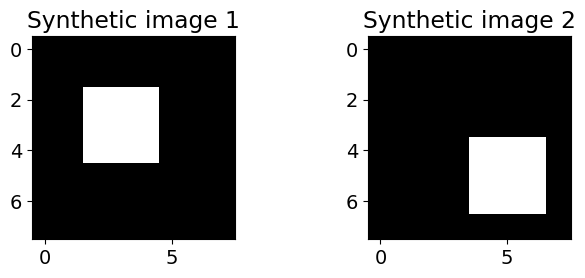

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(7, 3))  # 입력 두 장을 확인합니다.
axes[0].imshow(images[0], cmap="gray", vmin=0, vmax=1)  # 첫 가상 영상입니다.
axes[0].set_title("Synthetic image 1")  # 왼쪽 제목입니다.
axes[1].imshow(images[1], cmap="gray", vmin=0, vmax=1)  # 둘째 가상 영상입니다.
axes[1].set_title("Synthetic image 2")  # 오른쪽 제목입니다.
plt.tight_layout()  # 여백을 맞춥니다.
plt.show()  # 입력 모양과 공간 위치를 봅니다.

## 선택 B. RNN 문서에서 입력 모양 읽기

[RNN 공식 문서](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html): `batch_first=True`이면 입력은 `(N, L, F)`입니다. N은 기록 묶음 수, L은 시간 길이, F는 시점마다의 특징 수입니다. 아래는 **공정 두 번을 각각 네 시점에 걸쳐, 센서 두 개로 측정했다고 가정한 합성 예시**입니다. 기존 process.csv의 독립 행을 시간 순서로 바꿔 부르지 않습니다.

`output[:, -1, :]`는 모든 묶음에서 마지막 시점의 은닉 특징을 꺼냅니다. 마지막 시점의 결과 하나를 예측하는 작업을 가정한 선택입니다. 매 시점 예측이 목표라면 출력 선택과 정답 모양도 달라집니다. `batch_first`는 여기서 입력·output의 축 순서를 정하며 hidden의 모양은 여전히 `(층 수, N, 은닉 수)`입니다.

In [14]:
sequence = torch.tensor([  # 시간 기록 두 묶음을 텐서로 만듭니다.
    [[0.0, 0.1], [0.2, 0.2], [0.4, 0.3], [0.6, 0.4]],  # 첫 공정의 네 시점·두 센서입니다.
    [[0.6, 0.4], [0.4, 0.3], [0.2, 0.2], [0.0, 0.1]],  # 둘째 공정의 네 시점·두 센서입니다.
])  # 전체 모양은 (2, 4, 2)입니다.
rnn = nn.RNN(input_size=2, hidden_size=4, batch_first=True)  # 시점마다 센서 2개를 읽습니다.
sequence_output, last_hidden = rnn(sequence)  # 모든 시점의 특징과 마지막 은닉 상태입니다.
last_feature = sequence_output[:, -1, :]  # 마지막 시점의 특징 4개입니다.
rnn_head = nn.Linear(4, 1)  # 마지막 특징으로 결과 하나를 만듭니다.
rnn_output = rnn_head(last_feature)  # 아직 학습하지 않은 출력입니다.
print("입력:", sequence.shape, "시점별 출력:", sequence_output.shape)  # (2, 4, 2), (2, 4, 4)입니다.
print("마지막 은닉:", last_hidden.shape, "마지막 특징:", last_feature.shape)  # (1, 2, 4), (2, 4)입니다.
print("최종 출력:", rnn_output.shape)  # 공정 두 번에 결과 하나씩, (2, 1)입니다.
print("미학습 출력:", rnn_output.detach())  # 학습하지 않아 의미 있는 예측값은 아닙니다.

입력: torch.Size([2, 4, 2]) 시점별 출력: torch.Size([2, 4, 4])
마지막 은닉: torch.Size([1, 2, 4]) 마지막 특징: torch.Size([2, 4])
최종 출력: torch.Size([2, 1])
미학습 출력: tensor([[0.3323],
        [0.3337]])


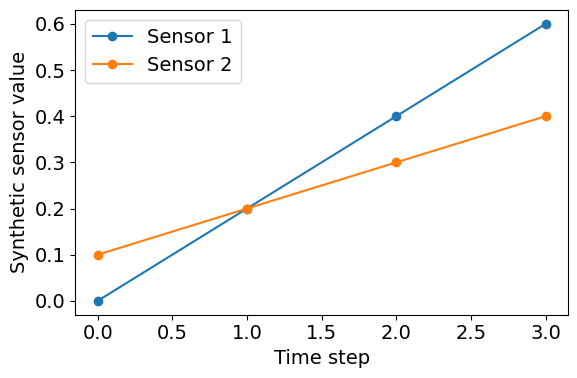

In [15]:
plt.figure(figsize=(6, 4))  # 첫 공정 묶음의 센서 기록입니다.
plt.plot(range(4), sequence[0, :, 0], marker="o", label="Sensor 1")  # 첫 센서의 시간 순서입니다.
plt.plot(range(4), sequence[0, :, 1], marker="o", label="Sensor 2")  # 둘째 센서의 시간 순서입니다.
plt.xlabel("Time step")  # 네 시점입니다.
plt.ylabel("Synthetic sensor value")  # 합성 숫자입니다.
plt.legend()  # 센서를 구분합니다.
plt.tight_layout()  # 여백을 맞춥니다.
plt.show()  # 시간 축의 의미를 확인합니다.

## 다른 아키텍처를 연결할 때 생각할 내용

1. 한 샘플의 뜻과 축 이름부터 씁니다. 표의 행인지, 영상 한 장인지, 시간 묶음인지 구별합니다.
2. 공식 문서의 Shape에서 입력 축 순서와 채널·특징 수를 확인합니다. 필요할 때만 `unsqueeze`, `permute`, `reshape`를 사용하고 전후 `shape`를 출력합니다. `reshape`는 숫자를 재배열할 뿐 축의 의미를 만들어 주지 않습니다.
3. 중간 출력 크기로 다음 층의 입력 수를 정합니다. CNN은 채널·공간 크기, RNN은 시간·은닉 크기를 확인합니다.
4. 무엇을 예측하는지에 맞춰 마지막 층과 정답·손실을 함께 정합니다. 여기서는 출력 하나인 회귀와 MSE를 사용했습니다. 분류는 정답 자료형과 logits·손실의 약속이 다릅니다.
5. 영상·시간 자료는 같은 웨이퍼나 로트가 학습과 시험에 섞이지 않도록 분리하고, 시간 문제는 미래 정보가 들어가지 않게 나눕니다.

### 공식 참고 문서

- [Dataset / DataLoader](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)
- [nn.Module](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html)
- [학습 반복문과 optimizer](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html)
- [Conv2d](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html)
- [RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html)
- [PyTorch 설치](https://pytorch.org/get-started/locally/)

기본 API 예제이며 제공된 실행 출력의 torch 버전은 첫 셀에서 확인합니다. 다른 버전의 문서에서는 선택 인자나 기본값이 달라질 수 있으므로 설치한 버전의 문서도 확인합니다.